# A balance sheet in 19 time bands: the repricing gap, the duration gap and a first EVE

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 to 04 of topic 01 (the engine, a `TestResult`, policies)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- place the cash flows of a balance sheet in the 19 standard time bands and say why the bands exist;
- read a repricing gap and the first-order effect on net interest income (NII) of a rate shift, and say what it leaves out;
- read a duration gap and the first-order effect on the value of equity, and say what it leaves out;
- discount the net cash flows into an economic value of equity (EVE) and explain why EVE is a present-value measure, not an accounting one;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is the valuation date 2022-06-30 (2022-Q2) of case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, as Contraste commits it. Two sources feed it, both in the licence class `mirror-allowed` (`conventions/third-party-datasets.md`):

- the **FDIC call reports** of the bank (FDIC BankFind financials, https://api.fdic.gov/banks/financials, public domain), which give the balance sheet by repricing band;
- the **US Treasury daily par yield curve** (https://home.treasury.gov/resource-center/data-chart-center/interest-rates, public domain), which gives the rates that discount the flows.

The bank is **real in aggregate and synthetic in behaviour**: the totals are the bank's own, but the call report holds no deposit behaviour, no prepayment history and no profile finer than its bands, so every such assumption is stated by Contraste and labelled synthetic in the document. Money is in USD thousands, rates are decimals with continuous compounding, and a positive delta EVE or delta NII is a **loss**.

- **Files read:** `data/derived/C14/vd-2022-q2.json` (`outputs.balance_sheet`, `ladder`, `curve`, `scenarios`, `units`, `sign_convention`) and `data/derived/C14/models-svb-2021-2022.json` (the bilingual labels of the 19 bands).

The next cell loads both files and prints what the document says about itself.

In [2]:
# Load the valuation date and the model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
doc = json.loads((derived / "vd-2022-q2.json").read_text(encoding="utf-8"))
models = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))
out = doc["outputs"]
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"behavioural": "behavioural", "contractual": "contractual", "asset": "asset", "liability": "liability",
        "real": "real", "synthetic": "synthetic", "thousands": "thousands", True: "yes", False: "no"}

print("valuation date:", out["valuation_date"], "| currency:", out["currency"], "| money scale:", NAME[out["units"]["money_scale"]])
print("bank:", out["bank"]["name"], "| aggregates:", NAME[out["bank"]["aggregates"]], "| behaviour:", NAME[out["bank"]["behaviour"]])
print(out["bank"]["notice"][LANG])
print(out["sign_convention"]["statement"][LANG])
print("baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

valuation date: 2022-06-30 | currency: USD | money scale: thousands
bank: Silicon Valley Bank | aggregates: real | behaviour: synthetic
The call-report aggregates are the bank's own, read from the FDIC BankFind financials. Every behavioural assumption (deposit core share and maturity, prepayment, term-deposit redemption, the slotting of the report bands) is synthetic and stated in the document.
A positive delta EVE or delta NII is a loss; only losses are aggregated across currencies.
baked by riskvalidation 0.8.1 | installed 0.8.1


## Method

The method has five steps: (1) the 19 bands, (2) slotting cash flows into them, (3) the repricing gap and its first-order effect on NII, (4) the duration gap, (5) the EVE. Every number is a call to the engine; the notebook assembles the inputs from the committed document and compares each result with what the document holds.

### Step 1: the 19 time bands

The standardised framework of the Basel Committee slots every interest-rate-sensitive cash flow into 19 time bands, from overnight to over 20 years, and represents each band by its midpoint (BCBS, SRP31.96, Table 3, https://www.bis.org/basel_framework/chapter/SRP/31.htm). A band is an interval $(\text{lower}, \text{upper}]$: a flow at exactly one month is in the first band that ends at one month. The engine's `bucket_grid` returns the edges, the midpoints and the labels. The next cell prints the grid.

In [3]:
# The engine's grid of 19 bands: the number of the band, its edges and its midpoint in years
grid = slotting.bucket_grid()
MID = grid.midpoints
print("bands:", len(MID))
print(f"{'band':>6s} {'lower (y)':>14s} {'upper (y)':>14s} {'midpoint (y)':>14s}")
for k in range(len(MID)):
    print(f"{k + 1:6d} {grid.lower[k]:14.4f} {grid.upper[k]:14.4f} {MID[k]:14.4f}")

bands: 19
  band      lower (y)      upper (y)   midpoint (y)
     1         0.0000         0.0028         0.0028
     2         0.0028         0.0833         0.0417
     3         0.0833         0.2500         0.1667
     4         0.2500         0.5000         0.3750
     5         0.5000         0.7500         0.6250
     6         0.7500         1.0000         0.8750
     7         1.0000         1.5000         1.2500
     8         1.5000         2.0000         1.7500
     9         2.0000         3.0000         2.5000
    10         3.0000         4.0000         3.5000
    11         4.0000         5.0000         4.5000
    12         5.0000         6.0000         5.5000
    13         6.0000         7.0000         6.5000
    14         7.0000         8.0000         7.5000
    15         8.0000         9.0000         8.5000
    16         9.0000        10.0000         9.5000
    17        10.0000        15.0000        12.5000
    18        15.0000        20.0000        17.5000
  

### Step 2: slotting cash flows into the bands

`bucket_of` gives the band number of a time and `slot_cash_flows` adds a list of amounts at given times into the 19 bands (assets positive, liabilities negative); the sum of the result equals the sum of the amounts, so slotting moves money between bands and never creates or destroys it. The next cell slots a small example by hand-chosen times: a bullet loan of 1,000 maturing in 5 years, a deposit of 400 repricing in 2.3 years and a deposit of 300 repricing in exactly one month.

In [4]:
# Slot three flows by hand: the band of each time, then the 19-band vector and its conservation of money
times = np.array([5.0, 2.3, 1 / 12])
amounts = np.array([1000.0, -400.0, -300.0])
for t, a in zip(times, amounts):
    print(f"time {t:7.4f} years, amount {a:8.1f} -> band {slotting.bucket_of(t, grid)}")
slotted = slotting.slot_cash_flows(times, amounts, grid)
print("non-zero bands:", {k + 1: float(v) for k, v in enumerate(slotted) if v != 0.0})
print("sum of the slotted flows:", float(slotted.sum()), "| sum of the amounts:", float(amounts.sum()))

time  5.0000 years, amount   1000.0 -> band 11
time  2.3000 years, amount   -400.0 -> band 9
time  0.0833 years, amount   -300.0 -> band 2
non-zero bands: {2: -300.0, 9: -400.0, 11: 1000.0}
sum of the slotted flows: 300.0 | sum of the amounts: 300.0


### The committed balance sheet

The bank's balance sheet has 17 items (8 assets and 9 liabilities). The pipeline slotted each one into the 19 bands with the engine and committed the result twice: with the **behavioural** treatment of non-maturity deposits (the part the standard calls stable is spread over time, capped by the standard) and with the **contractual** treatment (every such deposit overnight). The next cell lists the items with their amounts and checks that the totals of the document are the sums of the items.

In [5]:
# List the items of the balance sheet and check the totals of the document against the sum of the items
items = out["balance_sheet"]["items"]
for it in items:
    print(f"{it['item_id']:4s} {NAME[it['side']]:9s} {it['amount']:16,.0f}  {it['label'][LANG]}")
assets = sum(it["amount"] for it in items if it["side"] == "asset")
liabilities = sum(it["amount"] for it in items if it["side"] == "liability")
print("assets:", round(assets), "| document:", round(out["balance_sheet"]["total_assets"]))
print("liabilities:", round(liabilities), "| document:", round(out["balance_sheet"]["total_liabilities"]))
print("equity (assets minus liabilities):", round(assets - liabilities))

A1   asset           14,269,000  Cash and balances due from depository institutions
A2   asset              539,000  Federal funds sold and reverse repurchase agreements
A3   asset           95,814,000  Securities held to maturity
A4   asset           26,130,000  Securities available for sale
A5   asset           55,065,000  Loans repricing within three months
A6   asset            7,748,000  Fixed-rate commercial and other loans
A7   asset            8,048,000  Closed-end residential loans (prepayable)
A8   asset            4,211,000  Other assets, net of the allowance, and loans without a repricing band
L1   liability        2,723,410  Noninterest-bearing deposits, retail
L2   liability      113,453,590  Noninterest-bearing deposits, wholesale
L3   liability        1,726,590  Interest-bearing non-maturity deposits, retail
L4   liability       71,927,410  Interest-bearing non-maturity deposits, wholesale
L5   liability          322,000  Time deposits
L6   liability        3,500,000  F

The 19-band vector of each item is in `cash_flows`. The next cell rebuilds the vectors of the assets and of the liabilities under each treatment: liabilities are stored as negative amounts, and the gap functions take magnitudes, so the liability vector is the negative of the stored sum. It checks that the total of each vector equals the sum of the items, the conservation seen above, now on the real book.

In [6]:
# Rebuild the 19-band vectors of assets and liabilities, behavioural and contractual, from the committed items
def to_vector(rows):
    vector = np.zeros(19)
    for row in rows:
        vector[row["bucket"] - 1] += row["amount"]
    return vector

flows = {}
for treatment in ("behavioural", "contractual"):
    a = sum(to_vector(it["cash_flows"][treatment]) for it in items if it["side"] == "asset")
    l = -sum(to_vector(it["cash_flows"][treatment]) for it in items if it["side"] == "liability")
    flows[treatment] = (a, l)
    print(f"{NAME[treatment]:12s} assets in the bands {a.sum():16,.0f} | liabilities in the bands {l.sum():16,.0f}")
print("items assets {:,.0f} | items liabilities {:,.0f}".format(assets, liabilities))

behavioural  assets in the bands      211,824,000 | liabilities in the bands      196,438,000
contractual  assets in the bands      211,824,000 | liabilities in the bands      196,438,000
items assets 211,824,000 | items liabilities 196,438,000


### Step 3: the repricing gap and the first-order effect on NII

The repricing gap of band $k$ is the assets minus the liabilities that reprice in it, $G_k = RSA_k - RSL_k$, in money. For a parallel shift $\Delta r$ and a one-year horizon on a constant balance sheet, the textbook earnings-gap approximation of the change in NII is

$$\Delta NII \approx \sum_{t_k < 1} G_k \,\Delta r\, (1 - t_k)$$

where $t_k$ is the midpoint of band $k$ in years: a gap that reprices early earns the new rate for the rest of the year. It ignores basis risk, options and new business (source: dossier 05, D.1, and the earnings-gap literature; BCBS requires NII sensitivity under the two parallel scenarios for disclosure, d368). The engine's `delta_nii_gap` reports it **loss-positive**, so a positive gap earns more when rates rise and returns a negative number. The next cell calls `repricing_gap` and `delta_nii_gap` for a +100 bp shift and compares with the committed ladder.

In [7]:
# Repricing gap by band and its first-order effect on NII for +100 bp, behavioural and contractual, against the committed ladder
ladder = {row["nmd_assumption"]: row for row in out["ladder"]}
gaps = {}
for treatment, (a, l) in flows.items():
    gaps[treatment] = eve_nii.repricing_gap(a, l)
    committed = np.array([r["gap"] for r in ladder[treatment]["repricing_gap"]])
    d_nii = eve_nii.delta_nii_gap(gaps[treatment], MID, 100.0)
    biggest = int(np.argmax(np.abs(gaps[treatment])))
    print(f"{NAME[treatment]:12s} largest gap {gaps[treatment][biggest]:16,.0f} in band {biggest + 1}")
    print(f"{'':12s} gap equals the committed one: {NAME[bool(np.allclose(gaps[treatment], committed))]}")
    print(f"{'':12s} delta NII for +100 bp (loss-positive): {d_nii:14,.0f} | committed {ladder[treatment]['delta_nii_gap_100bp_up']:14,.0f}")

behavioural  largest gap      -76,433,446 in band 1
             gap equals the committed one: yes
             delta NII for +100 bp (loss-positive):        199,057 | committed        199,057
contractual  largest gap     -172,807,898 in band 1
             gap equals the committed one: yes
             delta NII for +100 bp (loss-positive):      1,199,488 | committed      1,199,488


The effect is the sum of the contributions of the first six bands, those with midpoint under one year. The next cell shows each contribution for the behavioural gap, so the reader sees which band drives the result: the overnight gap is large and negative (the deposits that reprice at once), but its weight $1 - t_k$ is almost one, so it dominates. This is a check of the definition on the real book, not a second implementation of the function; the engine remains the method.

In [8]:
# Contribution of each band under one year to the loss-positive delta NII for +100 bp (a check of the definition)
gap = gaps["behavioural"]
near = MID < 1.0
contribution = -gap * 0.01 * (1.0 - MID)
for k in np.flatnonzero(near):
    print(f"band {k + 1:2d} midpoint {MID[k]:7.4f} gap {gap[k]:16,.0f} weight {1 - MID[k]:7.4f} contribution {contribution[k]:14,.0f}")
print("sum of the contributions:", round(float(contribution[near].sum())))
print("equal to the engine:", NAME[bool(np.isclose(contribution[near].sum(), eve_nii.delta_nii_gap(gap, MID, 100.0)))])

band  1 midpoint  0.0028 gap      -76,433,446 weight  0.9972 contribution        762,194
band  2 midpoint  0.0417 gap       19,035,377 weight  0.9583 contribution       -182,416
band  3 midpoint  0.1667 gap       39,236,232 weight  0.8333 contribution       -326,956
band  4 midpoint  0.3750 gap        4,907,151 weight  0.6250 contribution        -30,670
band  5 midpoint  0.6250 gap        4,668,329 weight  0.3750 contribution        -17,506
band  6 midpoint  0.8750 gap        4,471,798 weight  0.1250 contribution         -5,590
sum of the contributions: 199057
equal to the engine: yes


### Step 4: the duration gap and the first-order effect on equity

The duration gap compares how long the assets and the liabilities take, weighted by value, to repay in present-value terms. With the present value of the assets $A$ and of the liabilities $L$, and their value-weighted durations $D_A$ and $D_L$,

$$DGAP = D_A - \frac{L}{A}\, D_L, \qquad \Delta E \approx -DGAP \cdot A \cdot \Delta y$$

(source: dossier 05, D.2: a textbook first-order approximation with no single primary source). With continuous compounding the modified duration equals the Macaulay duration, the value-weighted average time. A positive gap means the assets are longer than the liabilities, so a rate rise lowers equity. The engine's `duration_gap` needs the flows, the zero rates at the midpoints and the midpoints; so first we need the rates.

#### The zero curve

The Treasury publishes **par yields** at 12 tenors; discounting needs **zero rates**. The engine's `bootstrap_zero_curve` turns the par yields into continuously compounded zero rates (semiannual bond-equivalent coupons, simple interest up to six months), and `zero_rates_at` interpolates them linearly in tenor, flat outside the grid, at the 19 midpoints. The next cell repeats both steps from the committed observed yields and compares with the zero rates the document carries.

In [9]:
# Bootstrap the zero curve from the observed par yields and read it at the 19 midpoints, against the committed zero rates
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
par = np.array([p["observed_yield"] for p in points])
zero = curves.bootstrap_zero_curve(tenors, par, 2)
r0 = curves.zero_rates_at(tenors, zero, MID)
print("curve kind:", out["curve"]["observed_kind"], "| tenors:", len(tenors), "| missing tenor (years):", out["curve"]["missing_tenors"])
print("zero rates equal the committed ones at the tenors:", NAME[bool(np.allclose(zero, [p["zero_rate"] for p in points]))])
print("zero rates equal the committed ones at the midpoints:", NAME[bool(np.allclose(r0, out["curve"]["zero_rates_at_midpoints"]))])
for k in (0, 5, 9, 14, 18):
    print(f"band {k + 1:2d} midpoint {MID[k]:7.4f} zero rate {r0[k]:.5f}")

curve kind: par-yield | tenors: 12 | missing tenor (years): [0.333333]
zero rates equal the committed ones at the tenors: yes
zero rates equal the committed ones at the midpoints: yes
band  1 midpoint  0.0028 zero rate 0.01279
band  6 midpoint  0.8750 zero rate 0.02711
band 10 midpoint  3.5000 zero rate 0.02977
band 15 midpoint  8.5000 zero rate 0.02988
band 19 midpoint 25.0000 zero rate 0.03257


#### The duration gap on the real book

Now the duration gap, for the behavioural and for the contractual treatment. The two treatments differ in the liabilities: with every non-maturity deposit overnight the liabilities have almost no duration, and the assets are much longer than the liabilities, so the gap is large.

In [10]:
# Duration gap of the book under each treatment, against the committed ladder
for treatment, (a, l) in flows.items():
    dg = eve_nii.duration_gap(a, l, r0, MID)
    c = ladder[treatment]["duration_gap"]
    print(NAME[treatment])
    print(f"  PV of assets {dg.asset_value:16,.0f} | PV of liabilities {dg.liability_value:16,.0f}")
    print(f"  duration of assets (y) {dg.asset_duration_years:7.4f} | duration of liabilities (y) {dg.liability_duration_years:7.4f}")
    print(f"  duration gap (y) {dg.duration_gap_years:7.4f} | equity change for +100 bp {dg.equity_change_100bp_up:14,.0f}")
    print("  equal to the committed values:", NAME[bool(np.isclose(dg.duration_gap_years, c["duration_gap_years"]) and np.isclose(dg.equity_change_100bp_up, c["equity_change_100bp_up"]))])

behavioural
  PV of assets      192,515,579 | PV of liabilities      185,478,799
  duration of assets (y)  2.8407 | duration of liabilities (y)  1.8656
  duration gap (y)  1.0433 | equity change for +100 bp     -2,008,492
  equal to the committed values: yes
contractual
  PV of assets      185,093,900 | PV of liabilities      196,381,326
  duration of assets (y)  3.8215 | duration of liabilities (y)  0.0128
  duration gap (y)  3.8079 | equity change for +100 bp     -7,048,257
  equal to the committed values: yes


### Step 5: the economic value of equity

The EVE is the present value of the net cash flows: the assets minus the liabilities, each discounted at its zero rate. With net cash flows $CF_k$ (assets positive, liabilities negative) and the zero rates $R_k$ at the midpoints (BCBS SRP31.129; dossier 05, D.2):

$$DF_k = \exp(-R_k\, t_k), \qquad EVE = \sum_{k=1}^{19} CF_k \, DF_k$$

It is a **present-value** measure: it asks what the balance sheet is worth today if every flow is paid as slotted, not what the books say. That is why it can be far from the accounting equity, and why the treatment of the deposits, which the books carry at par, moves it so much. The next cell computes the discount factors with `discount_factors` and the EVE with `eve`, and compares with the base EVE of the committed scenarios.

In [11]:
# Discount factors and the base EVE under each treatment, against the committed base EVE of the scenarios
df = curves.discount_factors(r0, MID)
print("discount factors at bands 1, 10 and 19:", [round(float(df[k]), 6) for k in (0, 9, 18)])
base = {}
for treatment, (a, l) in flows.items():
    base[treatment] = eve_nii.eve(a - l, r0, MID)
    committed = next(s["base_eve"] for s in out["scenarios"] if s["calibration"] == "2024" and s["nmd_assumption"] == treatment)
    print(f"{NAME[treatment]:12s} EVE {base[treatment]:16,.0f} | committed {committed:16,.0f} | equal {NAME[bool(np.isclose(base[treatment], committed))]}")
print("equity in the books:", round(assets - liabilities))

discount factors at bands 1, 10 and 19: [0.999964, 0.901054, 0.442993]
behavioural  EVE        7,036,780 | committed        7,036,780 | equal yes
contractual  EVE      -11,287,425 | committed      -11,287,425 | equal yes
equity in the books: 15386000


The last cell draws the gap by band for the two treatments, and the zero curve. On the left the behavioural gap shows the large negative overnight gap, which is the repricing deposits, and the long positive assets; the contractual gap is the same book with every deposit overnight, so the overnight gap is far more negative. On the right the zero curve at the 19 midpoints, the rates that discount every flow.

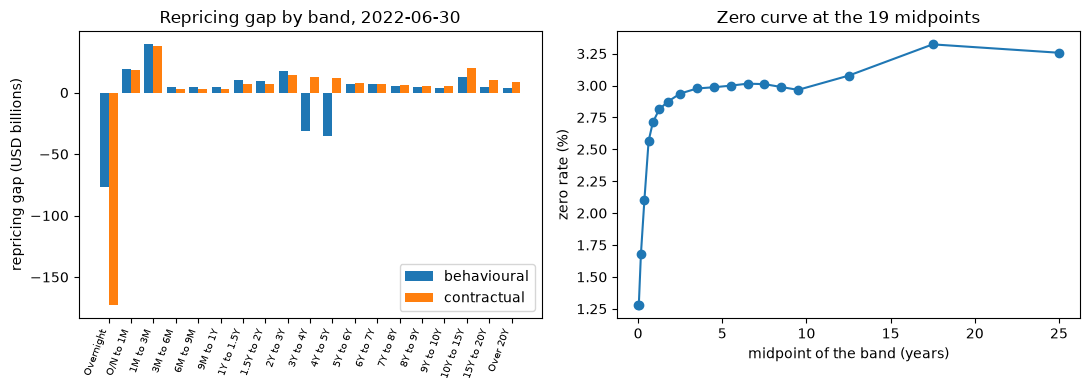

In [12]:
# Draw the repricing gap by band for the two treatments and the zero curve at the midpoints
labels = [b["label"][LANG] for b in models["fit"]["buckets"]]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
width = 0.4
x = np.arange(19)
left.bar(x - width / 2, gaps["behavioural"] / 1e6, width, label="behavioural")
left.bar(x + width / 2, gaps["contractual"] / 1e6, width, label="contractual")
left.set_xticks(x)
left.set_xticklabels(labels, rotation=70, ha="right", fontsize=7)
left.set_ylabel("repricing gap (USD billions)")
left.set_title("Repricing gap by band, 2022-06-30")
left.legend()
right.plot(MID, r0 * 100, marker="o")
right.set_xlabel("midpoint of the band (years)")
right.set_ylabel("zero rate (%)")
right.set_title("Zero curve at the 19 midpoints")
fig.tight_layout()
plt.show()

## Results

- **Slotting.** The three-flow example lands in bands 11, 9 and 2, and its total, 300, is unchanged. On the bank, 211,824,000 of assets and 196,438,000 of liabilities (USD thousands) sit in the bands under both treatments: the treatment of the non-maturity deposits changes where the liabilities are, never how much there is.
- **Repricing gap and NII.** With the behavioural treatment the largest gap is -76,433,446 in the overnight band and the first-order change in NII for +100 bp is a loss of 199,057, equal to the committed value. With every deposit overnight the gap in that band is -172,807,898 and the loss is 1,199,488. The overnight band contributes a loss of 762,194, and the five other bands under one year give back about 563,000, so the net 199,057 is the difference of larger numbers: a validator reads the whole ladder, not only its sum. The approximation holds the balance sheet constant, keeps one shift for every band and ignores options.
- **Duration gap.** The behavioural duration gap is 1.0433 years and the first-order change in equity for +100 bp is -2,008,492, 13 percent of the books' equity of 15,386,000. The contractual gap is 3.8079 years and the change is -7,048,257, 46 percent. The two numbers are first order: they say which way and roughly how much, not how much exactly, and they cannot see the floors, the options or a non-parallel shock.
- **EVE.** The base EVE is 7,036,780 under the behavioural treatment and -11,287,425 under the contractual one, against 15,386,000 of equity in the books. The EVE is a present value of the flows as slotted, so it differs from the accounting equity, and the whole gap between the two EVEs comes from one assumption, how long the non-maturity deposits stay. Notebook 03 takes that assumption apart.
- **What the notebook does not show.** The standard's six shocks (notebook 02) and the behavioural assumptions behind the stable part of the deposits (notebook 03). The document was baked by engine 0.8.1, the installed version, so each recomputation equals its committed value; the notebook prints both versions so that a reader with another engine sees the difference.

## Summary

- A balance sheet becomes 19 numbers per side: slotting moves each cash flow into the band of its repricing or maturity time and never changes the total.
- The repricing gap is assets minus liabilities by band; its first-order effect on NII keeps only the bands under one year, weighted by the time left in the year.
- The duration gap is the difference between the value-weighted durations of assets and liabilities, scaled by the leverage; it gives the first-order effect on equity.
- The EVE is a present value, and the treatment of non-maturity deposits moves it by more than the books' equity.
- Both approximations are first order and ignore options and basis risk; the next notebooks replace them with the standard's six shocks and with the behavioural layer.

**What to try next.** Change the +100 bp shift of `delta_nii_gap` to -100 bp and read the sign. Then continue with notebook 02, the six standard shocks.

## References

- BCBS, Standards: Interest rate risk in the banking book, SRP31, Table 3 (the 19 time buckets) and SRP31.129 (the standardised EVE). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- FDIC, BankFind financials (call reports), public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research (IRRBB and ALM models), sections D.1 and D.2: the earnings-gap and duration-gap approximations.